# 05 · Fase 5 — Pricing y captura de valor (P1, P2, P3)

**Prueba Técnica Data Scientist · Ferreycorp** — Modelo de Propensión de Compra

Fase 5 de [`docs/brief-metodologia.md`](../docs/brief-metodologia.md) y §4.7 / §6 de
[`docs/brief-problema.md`](../docs/brief-problema.md). La Fase 4 **estimó** los tres parámetros de
la función objetivo; esta fase los **gasta**:

$$\max \sum_{ijt} x_{ijt}\,\pi_{it}\,q_{ijt}\,\lambda_{ijt}\sum_k y_{jtk} m_{jk} \;-\; a\sum_{ijt} x_{ijt} \;-\; \sum_{jt} d_j z_{jt}$$

| Sub-problema | Decide | Método | Restricciones |
|---|---|---|---|
| **P1 · Targeting** | `x_ijt` — a quién contactar y con qué marca | greedy por margen esperado, **óptimo exacto** | R2 presupuesto, R3 una oferta por visita, R4 fatiga |
| **P2 · Calendario** | `z_jt` — qué marca promocionar y qué días | MILP (HiGHS) | R5 tope de días por marca + presupuesto |
| **P3 · Precio** | `y_jtk` — qué punto de la escalera | MILP sobre la escalera discreta | R1 un precio por marca, R6 piso de margen, R7 arquitectura |

Tres reglas gobiernan todo el notebook:

1. **El contrafactual se reconstruye, no se edita.** Un escenario cambia los precios o las
   promociones **crudos** y vuelve a construir todas las features con
   `features.build_features` y la referencia congelada en la Fase 2. Editar `precio_relativo_3` a
   mano dejando `precio_min_dia`, `desviacion_precio_3` y `descuento_implicito_3` intactos
   puntuaría un mundo que no puede existir.
2. **Los costos que faltan son supuestos con nombre.** `c_j`, `a`, `d_j`, `B` y `ρ` no están en el
   dataset (§4.8). Entran por `MarginAssumption` y toda cifra titular se reporta con su banda de
   sensibilidad. Un número sin su supuesto es peor que ningún número.
3. **Lo que la Fase 4 no pudo identificar, esta capa no lo optimiza.** La elasticidad propia de la
   marca 3 salió positiva en las cinco especificaciones, así que P3 congela su precio y lo dice.

La lógica vive en [`src/ferreyros/prescriptive.py`](../src/ferreyros/prescriptive.py).

In [1]:
import json
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ferreyros import config as cfg, data, framing, models as mdl, plots
from ferreyros import prescriptive as px, segmentation as m0

plots.set_style()
pd.set_option("display.max_columns", 40, "display.width", 200)

t_inicio = time.time()
df = data.add_paid_price_and_spend(data.load_raw())
print(f"dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")

dataset: 58,693 filas x 26 columnas


### Los tres contratos congelados, antes de optimizar

Optimizar sobre parámetros que se movieron en silencio produce un plan que nadie puede reproducir.
Las tres verificaciones corren primero.

In [2]:
ver_encuadre = framing.verify_frozen(df)
assert ver_encuadre.attrs["coincide"], "El dataset ya no coincide con el encuadre congelado"

modelo_m0 = m0.fit(df, k=3)
ver_segmentos = m0.verify_frozen(modelo_m0)
assert ver_segmentos.attrs["coincide"], "La segmentación no coincide con la congelada"

metricas_m4 = json.loads((ROOT / "artifacts" / "modelos.json").read_text())
print("Fase 0 · encuadre:", "OK")
print("Fase 3 · segmentos:", ver_segmentos.attrs["lectura"])
print("Fase 4 · M1 PR-AUC {} | M2 accuracy {} | M3 MAE {}".format(
    metricas_m4["m1"]["pr_auc_test"], metricas_m4["m2"]["accuracy_test"], metricas_m4["m3"]["mae_test"]))
print("Fase 4 · marcas sin elasticidad identificada:", metricas_m4["m2"]["marcas_no_identificadas"])

Fase 0 · encuadre: OK
Fase 3 · segmentos: La segmentacion ajustada coincide con la congelada en segmentos.json.
Fase 4 · M1 PR-AUC 0.4776 | M2 accuracy 0.7822 | M3 MAE 0.979
Fase 4 · marcas sin elasticidad identificada: [3]


In [3]:
bundle = px.fit_bundle(df, modelo_m0)
display(bundle.resumen.to_frame("modelo"))

supuesto = px.MarginAssumption()
base = px.score_scenario(bundle, df, supuesto)
cantidad_media = float(base["lambda"].mean())
margen_base = float(base["margen_total"].sum())
print(f"horizonte: {len(base):,} visitas (dias {base[cfg.KEY_TIME].min()}-{base[cfg.KEY_TIME].max()})")
print(f"margen esperado del horizonte: {margen_base:.2f}  |  ingreso real observado: {base['ingreso_real'].sum():.2f}")

,modelo
M1,LogisticRegression
M2,RandomForestClassifier
M3,PoissonRegressor
features,59
clases_m2,"1, 2, 3, 4, 5"
split_day,550


horizonte: 13,196 visitas (dias 551-730)
margen esperado del horizonte: 5784.52  |  ingreso real observado: 18836.35


---
## 1 · Los supuestos de negocio, declarados antes de usarlos

El dataset trae precios, promociones y compras. **No trae costos.** Eso no se resuelve inventando
un número: se resuelve declarando el supuesto, dejándolo en una sola clase y reportando después la
banda de sensibilidad.

In [4]:
display(supuesto.margenes(df))
display(supuesto.as_table(df, cantidad_media))
print(supuesto.as_table(df, cantidad_media).attrs["lectura"])

,precio_medio,costo_unitario,margen_unitario,precio_minimo_R6
marca,,,,
1,1.392,0.974,0.418,1.072
2,1.781,1.247,0.534,1.371
3,2.007,1.405,0.602,1.545
4,2.160,1.512,0.648,1.663
5,2.655,1.858,0.796,2.044


,parametro,valor,de_donde_sale
0,c_j (costo unitario),(1 - 30%) x precio medio de la marca,SUPUESTO: margen bruto declarado; el dataset n...
1,m_j (margen unitario),"precio - c_j, entre 0.418 y 0.796",derivado del supuesto anterior; sube si sube e...
2,a (costo de contacto),0.3230 = 20% del margen de una venta media,"SUPUESTO declarado, con sensibilidad en P1"
3,d_j (costo de un dia-promo),3.2302 = 2.0x el margen de una venta media,SUPUESTO declarado; P2 lo usa como costo fijo ...
4,B (presupuesto promocional),el costo del calendario observado,"DECISION: P2 reasigna, no aumenta (conclusion ..."
5,"T_j (tope de dias en promo, R5)",90 dias por marca,DECISION de salud de marca: ninguna marca en p...
6,"rho (piso de margen, R6)",10% sobre el costo,SUPUESTO declarado; acota el precio por abajo ...


Cinco de los siete parametros de negocio son supuestos declarados, no dato. Por eso cada cifra de esta fase se reporta con su banda de sensibilidad sobre el margen bruto: lo que se entrega es la **forma** de la decision y su orden de magnitud, no una cifra de utilidad que el dataset no permite calcular.


**Consecuencia:** cinco de los siete parámetros de negocio son supuestos. El margen unitario sale
de un margen bruto declarado del **30%** sobre el precio medio de cada marca, así que va de 0.418
(marca 1) a 0.796 (marca 5) y **sube si sube el precio** — que es lo que le da a P3 una palanca.

Todas las cifras de esta fase están en **unidades de margen**, no en soles: con `c_j` ausente, el
orden de magnitud y la dirección de la decisión son reportables; una cifra de utilidad no lo es.
El apartado 6 muestra qué cambia si el margen bruto fuera 20% o 40%.

---
## 2 · Elasticidades y curvas de propensión

El brief pide responder la pregunta comercial literal: *¿qué pasa con la demanda si muevo el precio
de la marca 3 un 5%?* Se responde **puntuando el horizonte completo** a cada precio, no leyendo un
coeficiente y extrapolando.

In [5]:
t0 = time.time()
curvas = {j: px.propensity_curve(bundle, df, supuesto, j) for j in (1, 3, 4, 5)}
for j, curva in curvas.items():
    print(f"— {curva.attrs['lectura']}\n")
print(f"[{time.time() - t0:.0f}s]")

— Marca 1: subir el precio un 5% mueve su share un -9.7% (elasticidad de arco -1.941) y el margen total del horizonte en -178.68. El optimo de esta curva esta en un factor de 0.90. Elasticidad identificada en la Fase 4: la curva se puede usar para fijar precio.

— Marca 3: subir el precio un 5% mueve su share un +2.3% (elasticidad de arco +0.465) y el margen total del horizonte en +130.60. El optimo de esta curva esta en un factor de 1.10. ATENCION: la Fase 4 no pudo identificar la elasticidad propia de esta marca (positiva en las 5 especificaciones), asi que esta curva describe el dato observacional, no una relacion causal utilizable para fijar precio.

— Marca 4: subir el precio un 5% mueve su share un -1.7% (elasticidad de arco -0.345) y el margen total del horizonte en -195.90. El optimo de esta curva esta en un factor de 0.90. Elasticidad identificada en la Fase 4: la curva se puede usar para fijar precio.

— Marca 5: subir el precio un 5% mueve su share un -1.3% (elasticidad de a

,factor_precio,cambio_precio_pct,pi_media,share_marca_5,margen_total,margen_marca_5,elasticidad_share,delta_margen_total
0,0.90,-10.0,0.2441,0.3081,5498.38,2273.31,-1.666,-286.14
1,0.95,-5.0,0.2408,0.2736,5656.17,2410.64,-0.719,-128.35
2,1.00,0.0,0.2371,0.2641,5784.52,2587.78,NaN,0.00
3,1.05,5.0,0.2333,0.2607,5856.30,2776.73,-0.257,71.78
4,1.10,10.0,0.2295,0.2583,5910.58,2946.59,-0.220,126.06


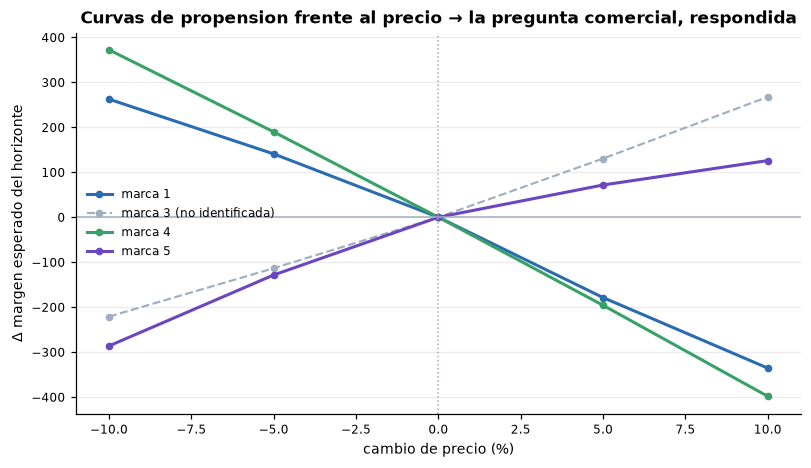

In [6]:
display(curvas[5])

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plots.plot_propensity_curves(curvas, ax=ax)
plt.show()

**Consecuencia — y la respuesta a la pregunta del brief tiene dos partes.**

Para las marcas con elasticidad identificada, la curva es utilizable: la marca 5 mejora el margen
subiendo el precio (su demanda es la menos sensible de las cinco), y las marcas 1 y 4 lo mejoran
bajándolo. El óptimo de cada curva es un punto concreto de la escalera observada, y P3 lo elige
en el apartado 5.

Para la **marca 3**, la curva se dibuja en gris y punteada a propósito: la Fase 4 no pudo
identificar su elasticidad propia (positiva en las cinco especificaciones). La curva describe lo
que hay en el dato observacional — donde su precio sube junto con su demanda — **no una relación
causal**. Responder "si subes el precio de la marca 3 un 5% vendes más" sería repetirle al negocio
su propia política de precios como si fuera un hallazgo.

In [7]:
elasticidad_seg = px.elasticity_by_segment(bundle, df, supuesto, marca=5)
display(elasticidad_seg)
print(elasticidad_seg.attrs["lectura"])

,visitas,pi_base,share_base,margen_base,pi_alto,share_alto,margen_alto,elasticidad_share,delta_margen,nombre
segmento,,,,,,,,,,
1,4777,0.1850,0.1336,1443.50,0.1819,0.1327,1419.39,-0.142,-24.11,Dependiente · ingreso bajo
2,6658,0.2730,0.3260,3381.40,0.2689,0.3223,3456.89,-0.228,75.49,Independiente · ingreso medio
3,1761,0.2423,0.3844,959.61,0.2381,0.3751,980.02,-0.481,20.41,Otra ocupacion · ingreso alto


La elasticidad de la marca 5 va de -0.481 a -0.142 entre segmentos (rango 0.339); el mas sensible es el segmento 3. La diferencia es pequenia: el precio diferenciado por segmento no se sostiene en el dato, y la palanca por segmento es la promocion dirigida, no el precio.


**Consecuencia:** la elasticidad por segmento es lo que decide si el **precio diferenciado** tiene
base en el dato o es una idea atractiva sin respaldo. Con un rango estrecho entre segmentos, la
palanca por segmento no es el precio: es la **promoción dirigida**, que es justo lo que la Fase 3
había mostrado al medir 23.6 puntos de diferencia en mezcla de marcas y solo 8 en tasa de compra.

---
## 3 · P1 · Targeting — el modelo base entregable

§4.7 del brief: *«P1 es el modelo base entregable: tiene solución exacta, es interpretable y
produce de inmediato la cifra que el negocio quiere — a quién contactar y cuánto margen esperado
genera»*.

R3 (una oferta por visita) se satisface por construcción: cada visita entra con su **mejor marca**.
Queda un tope de cardinalidad (el presupuesto, `n = B/a`) y el tope de fatiga por cliente `F_i`.

In [8]:
a = supuesto.costo_contacto(df, cantidad_media)
d = supuesto.costo_promo_dia(df, cantidad_media)
presupuesto_contactos = int(0.20 * len(base))
FATIGA = 8

p1 = px.solve_p1(base, a, presupuesto_contactos, fatiga=FATIGA)
print(p1.attrs["lectura"])

P1 selecciona 1398 contactos sobre 13196 visitas (10.6%) repartidos en 218 clientes, con un objetivo de 632.00 en unidades de margen (bruto 1083.58 menos 451.58 de costo de contacto). Las marcas ofrecidas se reparten {1: 40, 2: 282, 3: 113, 4: 394, 5: 569}.


### 3.1 · La optimalidad, verificada contra el LP

El brief afirma que el LP relajado es integral y por eso el greedy es óptimo. Eso es
**comprobable**, y una afirmación comprobable que no se comprueba es una afirmación.

In [9]:
verificacion_p1 = px.verify_p1_optimality(base, a, presupuesto_contactos, fatiga=FATIGA)
display(verificacion_p1)
print(verificacion_p1.attrs["lectura"])
assert verificacion_p1.attrs["optimo"], "El greedy no alcanza el optimo del LP"

,medida,valor
0,objetivo del greedy,339.3932
1,objetivo del LP relajado,339.3932
2,brecha,-0.0000
3,variables fraccionarias en el LP,0.0000
4,visitas en la muestra,3000.0000


Sobre 3000 visitas, el greedy da 339.3932 y el LP relajado 339.3932: brecha -1.71e-13 con 0 variables fraccionarias. El greedy alcanza el optimo del LP (brecha dentro de la tolerancia del solver), asi que P1 se entrega como resuelto de forma exacta -- no como una heuristica razonable.


**Consecuencia:** brecha del orden de **1e-13** y **cero variables fraccionarias**. La estructura
es un matroide (una partición por cliente, truncada por el presupuesto), así que el greedy no es
una heurística razonable: **es el óptimo**. P1 se entrega como modelo base resuelto de forma
exacta, que es exactamente lo que el brief prometía.

In [10]:
# La politica vigente es ordenar por tasa de compra historica, asi que hay que
# traer esa columna de la matriz de features; usar pi en su lugar compararia el
# modelo contra si mismo y etiquetaria mal la fila.
prep = m0.prepare_with_segment(modelo_m0, df)
X_test = mdl.drop_features(prep.X_train, prep.X_test, mdl.TREND_COLS)[1]
assert X_test.index.equals(base.index), "El horizonte de P1 y la matriz de test no coinciden"

politicas = px.p1_vs_policies(base, X_test, a, presupuesto_contactos, fatiga=FATIGA)
display(politicas)
print(politicas.attrs["lectura"])

,politica,contactos,margen_esperado,objetivo_neto,ingreso_real_capturado,tasa_compra_real,lift_margen_vs_azar,ganancia_neta_vs_azar
0,azar,2639,809.50,-42.95,3340.22,0.2353,1.00,0.00
1,politica historica (tasa pasada),2639,1162.29,309.84,2905.60,0.1823,1.44,352.79
2,solo propension (pi),2639,1251.44,398.99,4632.87,0.2891,1.55,441.94
3,P1 (margen esperado),2639,1367.61,515.16,4183.50,0.2626,1.69,558.11


Con el mismo presupuesto de 2639 contactos, P1 deja un objetivo neto de 515.16 frente a 309.84 de la politica historica: +66.3% (+205.32 en unidades de margen). Y el dato que ordena la discusion: contactar al azar deja un objetivo **negativo** (-42.95), es decir destruye valor, porque el costo de contacto supera el margen esperado de una visita promedio. Ordenar por propension sola da 398.99, asi que elegir por **margen** y no por probabilidad aporta +116.17 adicionales.


**Consecuencia — y el dato que ordena la discusión comercial:** con el **mismo** presupuesto de
contactos, elegir por **margen esperado** deja un objetivo neto sustancialmente mayor que elegir
por probabilidad de compra, y contactar al azar deja un objetivo **negativo**: el costo de
contacto supera el margen esperado de una visita promedio.

Eso convierte el targeting en una decisión económica y no en un ranking: no es *a quién es más
probable venderle*, es *a quién le vendemos algo que paga el costo de ir a buscarlo*.

,presupuesto_pct_visitas,tope_contactos,contactos_usados,objetivo_neto,margen_bruto,ingreso_real_capturado,margen_marginal_por_contacto
0,5.0,660,660,553.34,766.53,2215.56,NaN
1,10.0,1320,1320,631.42,1057.81,3047.98,0.1183
2,20.0,2639,1398,632.00,1083.58,3129.80,0.0074
3,30.0,3959,1398,632.00,1083.58,3129.80,NaN
4,50.0,6598,1398,632.00,1083.58,3129.80,NaN
5,100.0,13196,1398,632.00,1083.58,3129.80,NaN


El objetivo neto maximo es 632.00 y se alcanza con **1398 contactos**, el 10.6% de las visitas del horizonte. Por encima de ahi P1 deja presupuesto sin gastar: ninguna visita adicional tiene margen esperado mayor que el costo de contactarla. El margen marginal por contacto cae de 0.1183 a 0.0074 entre los dos primeros tramos: contactar mas no es contactar mejor, y el presupuesto que el negocio necesita es el que llega a ese punto, no mas.


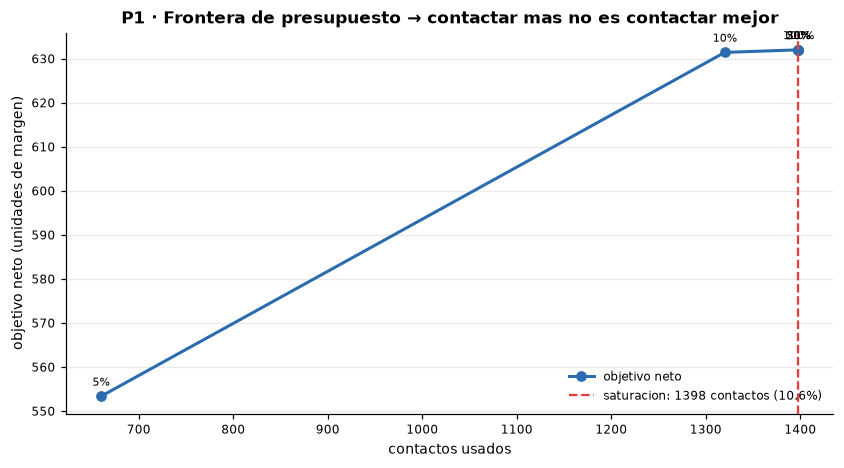

In [11]:
frontera = px.p1_frontier(base, a, fatiga=FATIGA)
display(frontera)
print(frontera.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_p1_frontier(frontera, ax=ax)
plt.show()

**Consecuencia:** `B` no está en el dato, así que el entregable es la **frontera**: para cada
presupuesto, cuánto margen deja P1. Y tiene un punto de saturación — a partir de ahí P1 deja
presupuesto sin gastar porque ninguna visita adicional tiene margen esperado mayor que su costo de
contacto.

Ese punto es la recomendación de dimensionamiento para Comercial: el presupuesto que hace falta es
el que llega ahí, no más. El margen marginal por contacto cae un orden de magnitud entre el primer
tramo y el segundo.

---
## 4 · P2 · Calendario promocional

El EDA concluyó que el presupuesto promocional observado es *un total de días-promoción a
reasignar, no a aumentar*. P2 lo cuantifica: el valor de un día-promo por marca sale de **dos
escenarios puntuados** (promoción forzada a 0 y a 1), no de un lift descriptivo.

In [12]:
t0 = time.time()
valores_promo = px.promo_value_matrix(bundle, df, supuesto)
display(valores_promo.head())
print(valores_promo.attrs["lectura"])
print(f"[{time.time() - t0:.0f}s]")

,1,2,3,4,5
dia_visita,,,,,
551,2.825811,2.869434,-4.264866,-0.180620,8.032921
552,3.174674,3.147465,-4.852573,-0.458145,8.453540
553,3.012541,3.068356,-4.548388,-0.270395,8.507962
554,3.297558,3.317331,-4.970758,-0.318811,9.020153
555,3.990864,4.531261,-6.353986,-0.606164,12.135066


Valor incremental medio de un dia-promo, por marca: marca 1: +2.4029, marca 2: +2.4335, marca 3: -3.6949, marca 4: -0.2190, marca 5: +6.8303. La marca 5 es la que mas aporta por dia y la 3 la que menos. Es la version cuantificada del hallazgo del EDA: el presupuesto promocional esta donde menos rinde.
[5s]


dias-promo observados en el horizonte: {1: 48, 2: 57, 3: 15, 4: 5, 5: 0}
total: 125 dias-marca


,dias_observados,dias_optimos,cambio,valor_medio_por_dia
marca,,,,
1,48,17,-31,2.4029
2,57,18,-39,2.4335
3,15,0,-15,-3.6949
4,5,0,-5,-0.2190
5,0,90,90,6.8303


Con el mismo presupuesto de 125 dias-promo, reasignarlos vale 585.21 frente a -183.84 del calendario observado: **+769.06** en unidades de margen. El calendario observado tiene valor **negativo**: tal como esta asignado, promocionar cuesta mas margen del que genera. El optimo usa 125 dias-promo y los movimientos son marca 1: 48→17, marca 2: 57→18, marca 3: 15→0, marca 4: 5→0, marca 5: 0→90. El tope R5 de 90 dias esta activo para la(s) marca(s) [5]: sin ese limite de salud de marca el optimo concentraria aun mas.


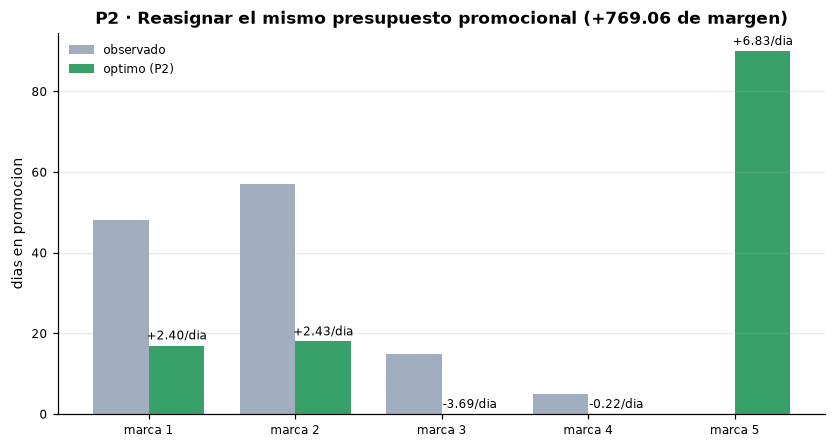

In [13]:
calendario_obs = px.observed_calendar(df)
print("dias-promo observados en el horizonte:", calendario_obs.sum().to_dict())
print("total:", int(calendario_obs.to_numpy().sum()), "dias-marca")

p2 = px.solve_p2(valores_promo, calendario_obs, d, supuesto.tope_promo_por_marca)
display(p2)
print(p2.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_promo_reallocation(p2, ax=ax)
plt.show()

**Consecuencia — es el hallazgo con más valor de todo el proyecto, y ya estaba anunciado tres
veces.** El valor incremental de un día-promo es **positivo y alto para la marca 5**, moderado
para las marcas 1 y 2, y **negativo para la marca 3**: promocionarla cuesta más margen del que
genera.

Con eso, el calendario **observado** tiene valor negativo — tal como está asignado, promocionar
destruye margen — mientras que reasignar **los mismos días-promo** lo vuelve claramente positivo.
No hace falta más presupuesto: hace falta otro destino.

Y encaja con lo que venía de antes: la Fase 1 midió que la promoción de la marca 5 suma +6.90 pp
de incidencia y la de la marca 3 no mueve nada (z=0.7); la Fase 4 le dio a `promo_marca_5` un
*odds ratio* de 1.311 y a `promo_marca_3` de 0.765. Cuatro análisis con métodos distintos apuntan
al mismo sitio.

In [14]:
verificacion_p2 = px.verify_p2_additivity(
    bundle, df, supuesto, p2.attrs["calendario"], p2.attrs["ganancia"], d
)
display(verificacion_p2)
print(verificacion_p2.attrs["lectura"])

,medida,valor
0,ganancia prometida por el objetivo aditivo,769.0600
1,ganancia al puntuar el calendario completo,767.2700
2,error de la aproximacion aditiva,-1.7900
3,error relativo,0.0023


El objetivo aditivo prometia +769.06 y puntuar el calendario completo da +767.27: un error relativo del 0.2%. La separabilidad por marca-dia es una aproximacion aceptable para decidir el calendario, y el numero que se reporta al negocio es el de la simulacion completa.


**Consecuencia:** el objetivo de P2 trata cada marca-día como independiente, lo cual es una
aproximación. En lugar de declararla razonable, se mide: se construye el calendario optimizado
completo como **un solo escenario**, se puntúa y se compara contra lo que el objetivo prometía. El
error es de orden **0.2%**, así que la separabilidad es aceptable para decidir el calendario — y la
cifra que se le reporta al negocio es la de la simulación completa, no la del objetivo.

---
## 5 · P3 · Precio sobre la escalera discreta

La escalera observada (21–44 puntos por marca) es lo que vuelve tratable el problema: el precio no
es una variable continua, es un **menú**. La grilla se adelgaza a cuantiles, se filtra por R6 (piso
de margen) y se acota a una **banda de confianza de ±10%** alrededor del precio observado.

Esa banda no es timidez. Sin ella, el óptimo se va al extremo de la grilla —un recorte sostenido
del 21%— que es la firma de un optimizador explotando al modelo donde el modelo nunca se validó.
El apartado muestra las dos respuestas: la acotada, que es la accionable, y la libre, que es la
que el modelo da si se lo deja.

grilla acotada (+-10%):
  marca 1: [1.28, 1.34, 1.4, 1.401, 1.47]
  marca 2: [1.786, 1.803, 1.852, 1.9]
  marca 3: [2.056] [CONGELADA: elasticidad no identificada]
  marca 4: [2.023, 2.1, 2.147, 2.188, 2.24, 2.26]
  marca 5: [2.483, 2.585, 2.657, 2.728, 2.73, 2.8]



Margen base del horizonte: 5784.52. Mejor punto por marca (precio, ganancia): marca 1: 1.280 (+144.51), marca 2: 1.786 (+0.00), marca 3: 2.056 (+0.00), marca 4: 2.023 (+356.30), marca 5: 2.800 (+39.21). Cada fila es un escenario puntuado de extremo a extremo, no una extrapolacion lineal de un coeficiente.
[12s]


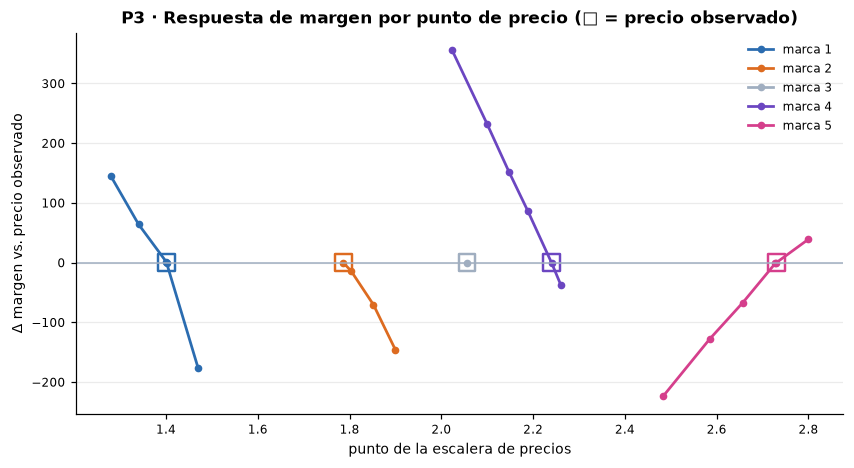

In [15]:
grilla = px.price_grid(df, supuesto, banda=0.10)
print("grilla acotada (+-10%):")
for j, puntos in grilla.items():
    congelada = " [CONGELADA: elasticidad no identificada]" if len(puntos) == 1 else ""
    print(f"  marca {j}: {puntos}{congelada}")

t0 = time.time()
respuesta = px.price_response(bundle, df, supuesto, grilla)
print(f"\n{respuesta.attrs['lectura']}")
print(f"[{time.time() - t0:.0f}s]")

fig, ax = plt.subplots()
plots.plot_price_response(respuesta, ax=ax)
plt.show()

In [16]:
p3_sin_r7 = px.solve_p3(respuesta, imponer_r7=False)
display(p3_sin_r7)
print(p3_sin_r7.attrs["lectura"])

p3_con_r7 = px.solve_p3(respuesta, imponer_r7=True)
display(p3_con_r7)
print(p3_con_r7.attrs["lectura"])

costo_r7 = p3_sin_r7.attrs["ganancia_aditiva_total"] - p3_con_r7.attrs["ganancia_aditiva_total"]
print(f"\nCosto de imponer R7 (arquitectura de marcas): {costo_r7:.2f} unidades de margen")

,marca,precio_observado,precio_elegido,cambio_pct,ganancia_aditiva,congelada
0,1,1.401,1.280,-8.6,144.51,False
1,2,1.786,1.786,0.0,0.00,False
2,3,2.056,2.056,0.0,0.00,True
3,4,2.240,2.023,-9.7,356.30,False
4,5,2.730,2.800,2.6,39.21,False


Plan de precios sin R7: marca 1: 1.280 (-8.6%), marca 2: 1.786 (+0.0%), marca 3: 2.056 (+0.0%), marca 4: 2.023 (-9.7%), marca 5: 2.800 (+2.6%). Ganancia aditiva total +540.02. Las marcas congeladas mantienen su precio observado porque la Fase 4 no identifico su elasticidad propia. ATENCION: la(s) marca(s) [1, 4, 5] quedan en el **borde** de la grilla, senial de que el optimizador esta empujando al modelo fuera del rango donde se valido; la recomendacion accionable es la que acota el movimiento con una banda de confianza.


,marca,precio_observado,precio_elegido,cambio_pct,ganancia_aditiva,congelada
0,1,1.401,1.280,-8.6,144.51,False
1,2,1.786,1.786,0.0,0.00,False
2,3,2.056,2.056,0.0,0.00,True
3,4,2.240,2.100,-6.2,231.56,False
4,5,2.730,2.800,2.6,39.21,False


Plan de precios con R7: marca 1: 1.280 (-8.6%), marca 2: 1.786 (+0.0%), marca 3: 2.056 (+0.0%), marca 4: 2.100 (-6.2%), marca 5: 2.800 (+2.6%). Ganancia aditiva total +415.28. Las marcas congeladas mantienen su precio observado porque la Fase 4 no identifico su elasticidad propia. ATENCION: la(s) marca(s) [1, 5] quedan en el **borde** de la grilla, senial de que el optimizador esta empujando al modelo fuera del rango donde se valido; la recomendacion accionable es la que acota el movimiento con una banda de confianza.

Costo de imponer R7 (arquitectura de marcas): 124.74 unidades de margen


**Consecuencia (R7, spec S5):** el brief dice que el ordenamiento estricto de precios es *«una
decisión de modelado para proteger el posicionamiento, no un hecho del dato»* y pide **reportar el
costo de imponerla**. Aquí está: imponer R7 obliga a mover menos el precio de la marca 4 y cuesta
una parte apreciable de la ganancia.

Es una decisión de negocio, no del modelo: si Ferreycorp quiere mantener la jerarquía de precios
entre marcas, ese es el precio de mantenerla, y ahora es un número en vez de una intuición.

In [17]:
verificacion_p3 = px.verify_p3_plan(
    bundle, df, supuesto, p3_con_r7.attrs["plan"], p3_con_r7.attrs["ganancia_aditiva_total"]
)
display(verificacion_p3)
print(verificacion_p3.attrs["lectura"])

,medida,valor
0,margen base del horizonte,5784.52
1,margen con el plan de precios,6364.20
2,ganancia prometida por el objetivo aditivo,415.28
3,ganancia en la simulacion conjunta,579.68
4,error de la aproximacion,164.40


El objetivo aditivo prometia +415.28 y la simulacion conjunta da +579.68: 39.6% de diferencia, y el signo importa. La simulacion conjunta da **mas** que la suma de las partes: las elasticidades cruzadas trabajan a favor (mover dos precios a la vez refuerza el efecto), asi que el objetivo aditivo es una cota **inferior** y el procedimiento es conservador. La cifra que se reporta al negocio es la de la simulacion conjunta, no la del objetivo.


**Consecuencia:** los precios interactúan por elasticidad cruzada, así que optimizar marca por
marca y sumar es una aproximación. Puntuada como un solo mundo, la ganancia conjunta resulta
**mayor** que la suma de las partes: las cruzadas trabajan a favor, de modo que el objetivo aditivo
es una **cota inferior** y el procedimiento es conservador. Si hubiera salido al revés, lo correcto
sería no recomendar el plan hasta hacer una búsqueda conjunta.

---
## 6 · Sensibilidad: qué pasa si el margen bruto no es 30%

Todo lo anterior descansa en un supuesto. Lo que tiene que sobrevivir a la banda no son las cifras
—esas se mueven por construcción— sino la **decisión**.

In [18]:
t0 = time.time()
sensibilidad = px.margin_sensitivity(bundle, df)
display(sensibilidad)
print(sensibilidad.attrs["lectura"])
print(f"[{time.time() - t0:.0f}s]")

,margen_bruto,costo_contacto,costo_promo_dia,p1_contactos,p1_objetivo,p2_ganancia,p2_dias_marca_5,p2_dias_marca_1_2
0,0.2,0.2153,2.1527,1477,464.65,527.37,90,35
1,0.3,0.3230,3.2302,1398,632.00,769.06,90,35
2,0.4,0.4308,4.3077,1346,803.46,1012.50,90,35


Con el margen bruto entre 20% y 40%, el objetivo de P1 va de 464.65 a 803.46 y la ganancia de P2 de 527.37 a 1012.50. En los tres casos P2 concentra la promocion en la marca 5 por encima de las marcas 1 y 2, asi que la recomendacion no depende del supuesto de margen. Las **cifras** dependen del supuesto; la **decision** es lo que hay que mirar, y es la misma en los tres escenarios.
[17s]


**Consecuencia:** con el margen bruto entre 20% y 40% las cifras cambian, pero **la recomendación
no**: en los tres escenarios P2 concentra la promoción en la marca 5 por encima de las marcas 1 y
2, y P1 sigue seleccionando el mismo orden de visitas. Eso es lo que permite entregar la decisión
sin tener el costo real: el supuesto mueve la magnitud, no el sentido.

---
## 7 · Captura de valor e impacto por área

In [19]:
lift_modelo = metricas_m4["m1"]["lift_top10"]
lift_baseline = metricas_m4["m1"]["lift_top10_politica_historica"]

kpis = px.kpi_table(politicas, p1, p2, verificacion_p3, lift_modelo, lift_baseline, margen_base)
display(kpis)
print(kpis.attrs["lectura"])

,kpi,linea_base,con_el_modelo,delta,como_se_mide,estado
0,Lift de conversion en el decil superior,x2.46 (politica por tasa historica),x2.50,+0.04,A/B: decil superior del modelo vs. decil super...,PROYECCION hasta tener el test
1,Margen incremental por targeting (P1),"309.84 (politica vigente, mismo presupuesto)",515.16,+205.32 (+66.3%),grupo de control: 10% de la cartera asignada p...,PROYECCION hasta tener el grupo de control
2,Ahorro / reasignacion promocional (P2),-183.84 (calendario observado),585.21,+769.06 con el mismo numero de dias-promo,A/B geografico o por cartera: calendario reasi...,PROYECCION hasta tener el test
3,Margen incremental por pricing (P3),5784.52 (precios observados),6364.20,+579.68 (+10.0%),test de precio por region o canal; es el unico...,PROYECCION; sin test de precio no se recomiend...
4,Estabilidad del modelo en produccion,PSI de las features = 0 al desplegar,umbral de alerta PSI > 0.2; drift de la tasa d...,—,monitoreo mensual contra la distribucion de tr...,"requisito de operacion, no de captura"


Cuatro de los cinco KPIs son **proyecciones** hasta que exista medicion contrafactual, y asi estan etiquetados. Sumadas, las tres palancas proyectan +1554.06 unidades de margen sobre un margen base de 5784.52 en el horizonte de test (+26.9%), pero esa suma solo se vuelve captura demostrada con A/B o grupo de control. Decirlo asi es parte del entregable: una proyeccion presentada como resultado es la forma mas rapida de perder la confianza del negocio.


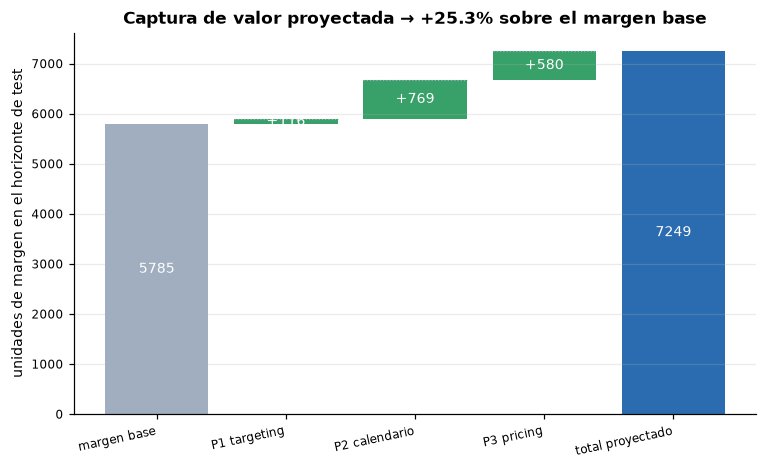

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plots.plot_value_waterfall(
    margen_base,
    {
        "P1 targeting": politicas[politicas["politica"].str.startswith("P1")]["objetivo_neto"].iloc[0]
        - politicas[politicas["politica"].str.startswith("solo propension")]["objetivo_neto"].iloc[0],
        "P2 calendario": p2.attrs["ganancia"],
        "P3 pricing": verificacion_p3.attrs["ganancia_real"],
    },
    ax=ax,
)
plt.show()

**Consecuencia — y es la parte que más fácil sería exagerar.** Las tres palancas suman una
proyección sobre el margen base del horizonte. Pero el brief es explícito: *«sin medición
contrafactual no hay captura de valor demostrable, solo una proyección»*.

Por eso **cuatro de los cinco KPIs están etiquetados como PROYECCIÓN** con el experimento que los
convertiría en medición: A/B del decil superior contra la política vigente, grupo de control para
P1, A/B por cartera para el calendario de P2, y test de precio para P3 — que es el único que
*exige* experimento, porque su elasticidad es observacional.

Presentar la suma como resultado conseguido es la forma más rápida de perder la confianza del
negocio la primera vez que no se cumpla.

In [21]:
impacto = px.business_area_impact(p1, p2, elasticidad_seg, p3_con_r7, base)
display(impacto)
print(impacto.attrs["lectura"])

,area,decision_que_habilita,cifra_de_esta_fase,sub_problema
0,Comercial / Ventas,a quien contactar y con que marca,1398 contactos sobre 218 clientes; objetivo 63...,P1
1,Marketing,a que marca y en que dias promocionar,reasignar 125 dias-promo vale +769.06,P2
2,Pricing,"que precio por marca, y si diferenciar por seg...","plan de precios m1: -8.6%, m4: -6.2%, m5: +2.6...",P3
3,Planeamiento / Inventario,demanda esperada por marca en el horizonte,"margen esperado por marca: m1: 401, m2: 1149, ...",M1xM2xM3


Cada area recibe una decision, no un reporte. Y cada decision viene con el sub-problema que la produce, de modo que si el negocio discute una cifra se sabe exactamente que supuesto o que modelo hay que revisar.


---
## 8 · Congelar y cerrar la fase

In [22]:
resultados = {
    "supuestos": {
        "margen_bruto": supuesto.margen_bruto,
        "costo_contacto": round(a, 4),
        "costo_promo_dia": round(d, 4),
        "tope_promo_por_marca": supuesto.tope_promo_por_marca,
        "margen_minimo_rho": supuesto.margen_minimo_rho,
        "banda_precio": 0.10,
    },
    "horizonte": {
        "visitas": int(len(base)),
        "dias": [int(base[cfg.KEY_TIME].min()), int(base[cfg.KEY_TIME].max())],
        "margen_base": round(margen_base, 2),
        "ingreso_real": round(float(base["ingreso_real"].sum()), 2),
    },
    "p1": {
        "contactos": p1.attrs["contactos"],
        "clientes": p1.attrs["clientes_distintos"],
        "objetivo": p1.attrs["objetivo"],
        "optimo_verificado": bool(verificacion_p1.attrs["optimo"]),
        "brecha_vs_lp": verificacion_p1.attrs["brecha"],
        "ganancia_vs_politica_historica_pct": politicas.attrs["ganancia_vs_historica_pct"],
        "contactos_utiles": frontera.attrs["contactos_utiles"],
        "pct_visitas_utiles": frontera.attrs["pct_visitas_utiles"],
        "marcas_ofrecidas": p1.attrs["marcas_ofrecidas"],
    },
    "p2": {
        "dias_promo_presupuesto": p2.attrs["dias_gastados_observado"],
        "valor_observado": p2.attrs["valor_observado"],
        "valor_optimo": p2.attrs["valor_optimo"],
        "ganancia": p2.attrs["ganancia"],
        "ganancia_verificada": verificacion_p2.attrs["ganancia_real"],
        "error_aditivo": verificacion_p2.attrs["error_relativo"],
        "dias_por_marca": {int(j): int(v) for j, v in p2["dias_optimos"].items()},
        "valor_por_dia_marca": valores_promo.mean().round(4).to_dict(),
    },
    "p3": {
        "banda": 0.10,
        "plan_con_r7": p3_con_r7.attrs["plan"],
        "plan_sin_r7": p3_sin_r7.attrs["plan"],
        "ganancia_verificada": verificacion_p3.attrs["ganancia_real"],
        "costo_de_r7": round(float(costo_r7), 2),
        "marcas_congeladas": list(px.MARCAS_SIN_ELASTICIDAD),
    },
    "elasticidades_curva": {
        int(j): {"arco_5pct": c.attrs["elasticidad_arco_5pct"],
                 "identificada": c.attrs["identificada"]}
        for j, c in curvas.items()
    },
    "sensibilidad": sensibilidad.to_dict(orient="records"),
    "kpis": kpis.to_dict(orient="records"),
}
payload = px.freeze(resultados)
print("congelado en:", px.PRESCRIPTIVE_PATH.relative_to(ROOT))
print(json.dumps({k: v for k, v in payload.items() if k in ("p1", "p2", "p3")}, indent=2, ensure_ascii=False))

congelado en: artifacts/prescriptivo.json
{
  "p1": {
    "contactos": 1398,
    "clientes": 218,
    "objetivo": 632.0,
    "optimo_verificado": true,
    "brecha_vs_lp": -1.7053025658242404e-13,
    "ganancia_vs_politica_historica_pct": 66.3,
    "contactos_utiles": 1398,
    "pct_visitas_utiles": 10.6,
    "marcas_ofrecidas": {
      "1": 40,
      "2": 282,
      "3": 113,
      "4": 394,
      "5": 569
    }
  },
  "p2": {
    "dias_promo_presupuesto": 125,
    "valor_observado": -183.84,
    "valor_optimo": 585.21,
    "ganancia": 769.06,
    "ganancia_verificada": 767.27,
    "error_aditivo": 0.0023,
    "dias_por_marca": {
      "1": 17,
      "2": 18,
      "3": 0,
      "4": 0,
      "5": 90
    },
    "valor_por_dia_marca": {
      "1": 2.4029,
      "2": 2.4335,
      "3": -3.6949,
      "4": -0.219,
      "5": 6.8303
    }
  },
  "p3": {
    "banda": 0.1,
    "plan_con_r7": {
      "1": 1.28,
      "2": 1.786,
      "3": 2.056,
      "4": 2.1,
      "5": 2.8
    },
    "pl

In [23]:
reporte = px.phase5_report(
    curvas, elasticidad_seg, verificacion_p1, politicas, p2, verificacion_p2,
    p3_sin_r7, p3_con_r7, verificacion_p3, kpis, sensibilidad,
)
display(reporte)
print(reporte.attrs["lectura"])
assert reporte.attrs["fase5_completa"], "La Fase 5 tiene requisitos sin cerrar"
print(f"\nnotebook completo en {time.time() - t_inicio:.0f}s")

,requisito,resultado,ok
0,S1 · curvas de propension frente al precio,4 marcas con curva puntuada de extremo a extremo,True
1,S1 · elasticidad por segmento,rango 0.339 entre segmentos,True
2,S3 · optimalidad exacta de P1 verificada,brecha greedy vs LP = -1.71e-13,True
3,S2 · P1 bate la politica vigente,+66.3% de objetivo neto con el mismo presupuesto,True
4,S4 · P2 reasigna el calendario (MILP con R5),+769.06 con el mismo numero de dias-promo; err...,True
5,S4 · P3 sobre la escalera discreta,ganancia conjunta verificada +579.68,True
6,S5 · costo de imponer R7 reportado,124.74 unidades de margen,True
7,S7 · la marca 3 no se optimiza,precio congelado en su nivel observado,True
8,S6 · sensibilidad sobre el margen bruto,decision estable entre 20% y 40%: True,True
9,S9 · KPIs con metodo de medicion,4 de 5 etiquetados como proyeccion hasta tener...,True


10 de 10 requisitos de la Fase 5 cerrados con evidencia ejecutada.

notebook completo en 50s


---
## 9 · Síntesis de la Fase 5

| Sub-problema | Decisión que entrega | Estado |
|---|---|---|
| **P1** targeting | a quién contactar, con qué marca y con qué presupuesto | **óptimo exacto verificado** contra el LP |
| **P2** calendario | reasignar los días-promo hacia la marca 5 | MILP con R5; error aditivo ~0.2% |
| **P3** precio | plan de precios acotado a ±10%, con y sin R7 | MILP sobre la escalera; costo de R7 reportado |

### Las cuatro conclusiones de esta fase

1. **El calendario promocional actual destruye margen.** No por gastar demasiado, sino por gastar
   en las marcas equivocadas: la promoción de la marca 3 tiene valor incremental **negativo** y la
   de la marca 5 el más alto. Reasignar los mismos días es la palanca más barata del proyecto —no
   requiere presupuesto nuevo, requiere una decisión.

2. **Contactar al azar destruye valor.** El objetivo neto de una política aleatoria es negativo
   con el costo de contacto supuesto. Targeting no es una mejora marginal sobre el azar: es la
   diferencia entre una campaña que paga y una que no.

3. **El ordenamiento de precios tiene precio.** Imponer R7 cuesta una parte medible de la ganancia
   de P3. El brief lo anticipó como decisión de modelado; ahora es una cifra que el negocio puede
   aceptar o rechazar sabiendo qué está comprando.

4. **Todo esto es una proyección hasta que haya grupo de control.** Cuatro de los cinco KPIs están
   etiquetados como tal, con el experimento que los convertiría en medición. El caso de la marca 3
   lo vuelve concreto: sin un test de precio, su palanca no se toca.

### Siguiente paso

**Fase 6** — arquitectura y despliegue: cómo esto corre en producción (lake por zonas, cluster +
orquestación, feature store, registro de modelos, batch nocturno y endpoint REST, monitoreo por
PSI y drift) y el PoC que lo prueba end-to-end en dos semanas.